In [1]:
'''
efficiency comparison between our new nns
'''

'\nefficiency comparison between our new nns\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib

In [10]:
import precision_recall as pr

In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


In [4]:
df_names = ["original", "flipped", "both", "dup"]

In [5]:
df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/"

In [6]:
df_paths = ["predsarrays/",
                "presdarrays_flipped/",
                "presdarrays_both/",
                "predsarrays_dup/"]

In [59]:
dfs_neg = {
    name: pd.read_csv(f"{df_neg_base_path+df_paths[i]}"+"df_matched")
    for i, name in enumerate(df_names)
}

In [60]:
dfs_pos = {
    name: pd.read_csv(f"{df_pos_base_path+df_paths[i]}"+"df_matched")
    for i, name in enumerate(df_names)
}

In [99]:
dfs_pos['original']

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star
0,0,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,732.318841,1123.210145,138,1132.0,1589.0,-1.210145,9,1,10.0
1,1,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,855.785714,2303.142857,56,2312.0,134.0,-1.142857,4,1,2.0
2,2,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,930.333333,1583.866667,15,1591.0,706.0,-2.866667,10,1,1.0
3,3,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1319.743169,1809.453552,183,1818.0,2123.0,-1.453552,3,1,2.0
4,4,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1326.230047,1322.638498,213,1331.0,1567.0,-1.638498,5,1,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30005,30005,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2090.823529,689.294118,17,772.0,2020.0,72.705882,8,1,1.0
30006,30006,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2126.750000,1544.750000,4,1556.0,2919.0,1.250000,1,1,146.0
30007,30007,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2597.529412,310.558824,34,320.0,1610.0,-0.558824,5,1,3.0
30008,30008,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2751.458333,1907.416667,24,1916.0,215.0,-1.416667,2,1,4.0


In [11]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [284]:
for key in dfs_neg.keys():
    # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
    num, df = get_efficiency(dfs_neg[key], df_implants_neg, threshold)
    break

/tmp/ipykernel_12122/921931626.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)


In [285]:
df

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
2,2,2,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,1340.500000,448.000000,4,458.0,1367.0,...,0,1,16.0,[],0.0,8.732125,1342.0,460.0,0.90,6.0
20,20,20,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,1331.878788,449.878788,33,458.0,1367.0,...,0,1,16.0,[21],0.0,0.171420,1342.0,460.0,0.90,6.0
29,29,29,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,2505.666667,2851.666667,3,2861.0,1404.0,...,3,1,1.0,[],0.0,2.357023,2518.0,2862.0,0.80,8.0
30,30,30,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,2509.600000,253.800000,5,263.0,828.0,...,8,1,1.0,[],0.0,1.788854,2518.0,263.0,0.50,9.0
31,31,31,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,2653.500000,1072.777778,18,1083.0,2422.0,...,4,1,1.0,[],0.0,1.320540,2663.0,1084.0,0.70,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24008,24008,24008,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1364.238095,958.158730,63,968.0,825.0,...,0,1,16.0,[],0.0,1.135004,1375.0,969.0,0.70,9.0
24015,24015,24015,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1806.547619,2355.071429,42,2366.0,541.0,...,2,1,8.0,[],0.0,2.414290,1818.0,2367.0,0.85,8.0
24017,24017,24017,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1969.333333,1909.166667,6,1918.0,2162.0,...,3,1,1.0,[],0.0,0.687184,1980.0,1919.0,0.90,5.0
24022,24022,24022,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2287.033898,428.288136,59,438.0,147.0,...,4,1,5.0,[],0.0,0.712671,2297.0,439.0,0.70,7.0


In [273]:
len(df22[df22['dist_to_implant']<=20])

234

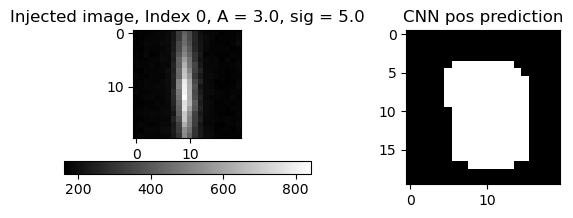

In [274]:
rff.inspect_stamp_and_map(df22, 0, pdirec=df_paths[0][:-1])

In [275]:
df22

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,732.318841,1123.210145,138,1132.0,1589.0,-1.210145,9,1,10.0,1.388679,743.0,1132.0,3.0,5.0
1,1,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,855.785714,2303.142857,56,2312.0,134.0,-1.142857,4,1,2.0,0.257539,866.0,2313.0,1.5,4.0
2,2,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,930.333333,1583.866667,15,1591.0,706.0,-2.866667,10,1,1.0,451.760772,1332.0,1819.0,3.0,8.0
3,3,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1319.743169,1809.453552,183,1818.0,2123.0,-1.453552,3,1,2.0,2.301954,1332.0,1819.0,3.0,8.0
4,4,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1326.230047,1322.638498,213,1331.0,1567.0,-1.638498,5,1,4.0,2.842590,1339.0,1332.0,6.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,ztf_20221020138241_000686_zi_c01_x_0023.,1,pos,1301.500000,1682.000000,4,1693.0,2913.0,1.000000,1,1,10.0,587.745055,731.0,1784.0,2.0,5.0
996,996,ztf_20221020138241_000686_zi_c01_x_0023.,1,pos,1356.000000,1799.000000,3,1810.0,1453.0,1.000000,5,1,6.0,635.491935,731.0,1784.0,2.0,5.0
997,997,ztf_20221020138241_000686_zi_c01_x_0023.,1,pos,1508.500000,1682.000000,2,1693.0,2913.0,1.000000,1,1,10.0,741.690805,1999.0,2257.0,4.0,4.0
998,998,ztf_20221020138241_000686_zi_c01_x_0023.,1,pos,1559.500000,1772.000000,2,1783.0,1737.0,1.000000,0,1,33.0,640.386797,1999.0,2257.0,4.0,4.0


In [141]:
get_efficiency(df2, df_implants_pos, 100)

/tmp/ipykernel_12122/813927168.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_cut.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], inplace=True)


5.008347245409015

In [62]:
print("neg-implantation image df lengths")
for key in dfs_neg.keys():
    print(key, len(dfs_neg[key]))
# len(dfs_neg['flipped']), len(dfs_neg['original'])

print("\npos-implantation image df lengths")
for key in dfs_pos.keys():
    print(key, len(dfs_pos[key]))
    
print("\nneg-implantation image num of neg detections")
for key in dfs_neg.keys():
    print(key, len(dfs_neg[key][dfs_neg[key]['type']=='neg']))
# len(dfs_neg['flipped']), len(dfs_neg['original'])

print("\npos-implantation image num of pos detectiions")
for key in dfs_pos.keys():
    print(key, len(dfs_pos[key][dfs_pos[key]['type']=='pos']))
    
print("\nneg-implantation image num of detections deduplicated")
for key in dfs_neg.keys():
    print(key, np.sum(dfs_neg[key]['is_smaller_dup']==0))
# len(dfs_neg['flipped']), len(dfs_neg['original'])

print("\npos-implantation image num of detections deduplicated")
for key in dfs_pos.keys():
    print(key, np.sum(dfs_pos[key]['is_smaller_dup']==0))
    
threshold = 20

print(f"\npos-implantation image efficiency of detecting implantations within {threshold}")
for key in dfs_pos.keys():
    # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
    cut_len, implant_len = get_efficiency(dfs_pos[key], df_implants_pos, threshold, 'pos')
    print(key, f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(dfs_pos[key])):.1f} %")
    
print(f"\nneg-implantation image efficiency of detecting implantations within {threshold}")
for key in dfs_neg.keys():
    # print(key, np.sum(dfs_pos[key])['is_smaller_dup']==0)
    cut_len, implant_len = get_efficiency(dfs_neg[key], df_implants_neg, threshold, 'neg')
    print(key, f"{(100*cut_len/implant_len):.1f} %, with precision {100*pr.precision(num_true_retrieved=cut_len, num_all_retrieved=len(dfs_neg[key])):.1f} %")


neg-implantation image df lengths
original 24036
flipped 202087
both 83315
dup 85884

pos-implantation image df lengths
original 30010
flipped 40308
both 41253
dup 19148

neg-implantation image num of neg detections
original 12744
flipped 158265
both 45484
dup 63356

pos-implantation image num of pos detectiions
original 24874
flipped 4059
both 33863
dup 4787

neg-implantation image num of detections deduplicated
original 16555
flipped 92804
both 49611
dup 48994

pos-implantation image num of detections deduplicated
original 18369
flipped 23574
both 23669
dup 12508

pos-implantation image efficiency of detecting implantations within 20
original 78.6 %, with precision 4.7 %
flipped 77.4 %, with precision 3.5 %
both 87.0 %, with precision 3.8 %
dup 81.7 %, with precision 7.7 %

neg-implantation image efficiency of detecting implantations within 20
original 71.8 %, with precision 5.4 %
flipped 82.2 %, with precision 0.7 %
both 78.2 %, with precision 1.7 %
dup 77.0 %, with precision 1.6 %


Text(0.5, 0, 'distance')

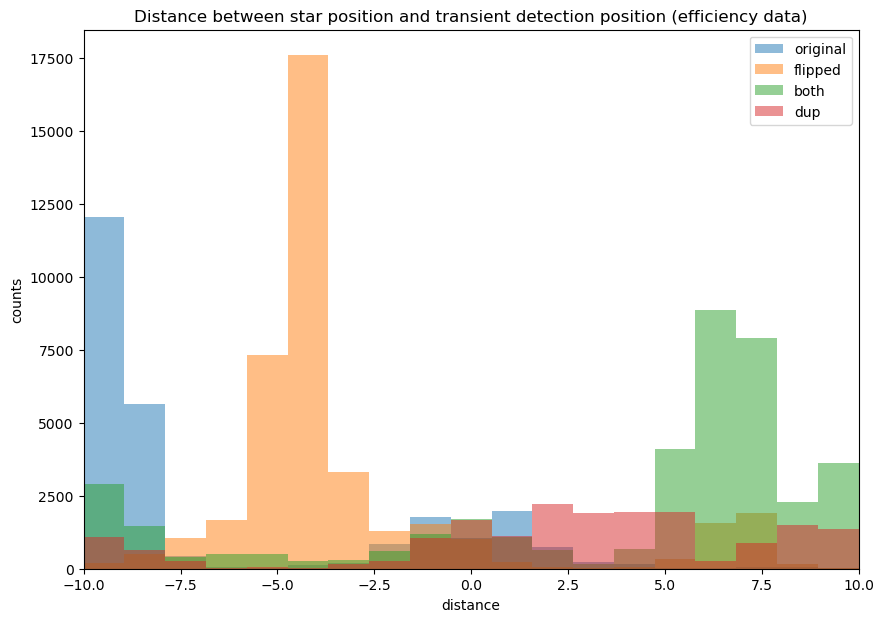

In [114]:
for key in dfs_pos.keys():
    plt.hist((dfs_pos[key]['closest_x']-(dfs_pos[key]['col_from_nn']+10)), 
             bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
plt.xlim(-10,10)
plt.legend()
plt.title("Distance between star position and transient detection position (efficiency data)")
plt.ylabel("counts")
plt.xlabel("distance")

In [79]:
dfs_pos[key]

,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star
0,0,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,732.318841,1123.210145,138,1132.0,1589.0,-1.210145,9,1,10.0
1,1,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,855.785714,2303.142857,56,2312.0,134.0,-1.142857,4,1,2.0
2,2,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,930.333333,1583.866667,15,1591.0,706.0,-2.866667,10,1,1.0
3,3,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1319.743169,1809.453552,183,1818.0,2123.0,-1.453552,3,1,2.0
4,4,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1326.230047,1322.638498,213,1331.0,1567.0,-1.638498,5,1,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30005,30005,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2090.823529,689.294118,17,772.0,2020.0,72.705882,8,1,1.0
30006,30006,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2126.750000,1544.750000,4,1556.0,2919.0,1.250000,1,1,146.0
30007,30007,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2597.529412,310.558824,34,320.0,1610.0,-0.558824,5,1,3.0
30008,30008,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,2751.458333,1907.416667,24,1916.0,215.0,-1.416667,2,1,4.0


Text(0.5, 0, 'number in same star streak')

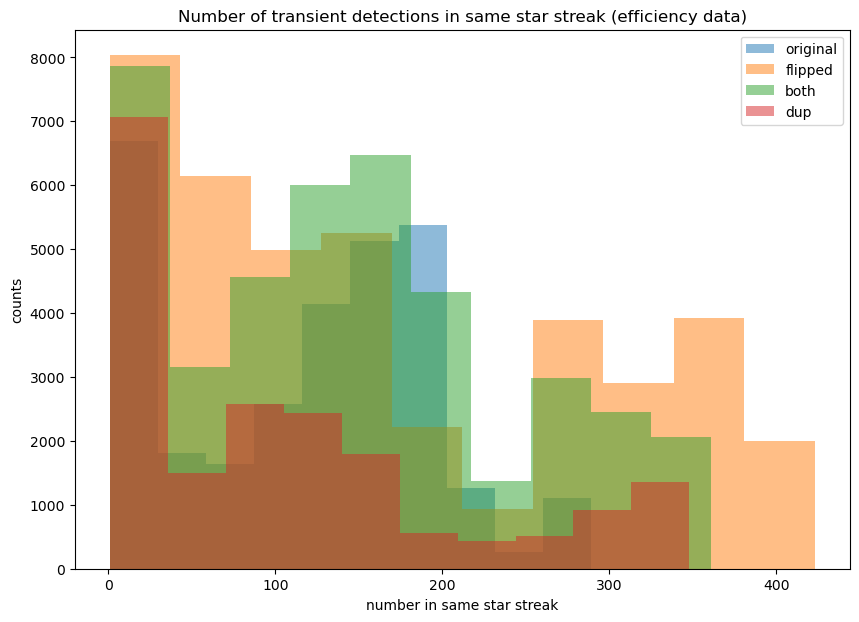

In [64]:
for key in dfs_neg.keys():
    plt.hist(dfs_pos[key]['num_in_file_in_star'], 
             # bins = np.linspace(-10,10,20),
            alpha=.5, label=key)
# plt.xlim(-10,10)
plt.legend()
plt.title("Number of transient detections in same star streak (efficiency data)")
plt.ylabel("counts")
plt.xlabel("number in same star streak")

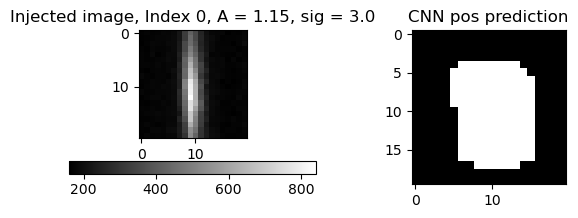

In [211]:
rff.inspect_stamp_and_map(dforiginal2, 0)

In [17]:
#okay so let's look at some examples where we're 10 pixels away
dfs_pos["original"][dfs_pos["original"]['Diff']==10]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
7883,7883,7883,ztf_20221017148750_000831_zi_c04_x_0012.,1,neg,1871.000000,93.0,5,113.0,238.0,...,7,1,1.0,[7882 7884],1.0,10.049876,1880.0,93.0,10.0,5.0
9784,9784,9784,ztf_20221017148750_000831_zi_c03_x_0015.,1,neg,298.500000,436.0,2,456.0,2060.0,...,0,1,9.0,[9782 9783],1.0,13.647344,315.0,458.0,6.0,8.0
18960,18960,18960,ztf_20221017148750_000831_zi_c03_x_0017.,1,neg,1649.000000,436.0,1,456.0,2060.0,...,0,1,8.0,[18958 18959 18961],1.0,14.422205,1667.0,458.0,8.0,8.0
23621,23621,23621,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,750.500000,214.0,2,234.0,1787.0,...,21,1,2.0,[23622],1.0,346.238718,440.0,93.0,1.1,8.0
23622,23622,23622,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,764.714286,214.0,7,234.0,1787.0,...,21,1,2.0,[23621],0.0,359.436577,440.0,93.0,1.1,8.0
26091,26091,26091,ztf_20220820237546_000798_zr_c14_x_0000.,1,pos,374.000000,2104.0,1,2124.0,1768.0,...,19,1,2.0,[],0.0,21.470911,365.0,2104.0,8.0,8.0


In [19]:
rff.inspect_stamp_and_map?

Signature:
rff.inspect_stamp_and_map(
    df,
    index,
    eff=True,
    posneg=None,
    size=10,
    column=None,
    nn_or_imp='nn',
    thr=True,
    star=False,
    direcname='1020',
    pdirec='predsarrays',
)
Docstring: for efficiency data
File:      ~/rwe/review_findings_functions.py
Type:      function

In [35]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

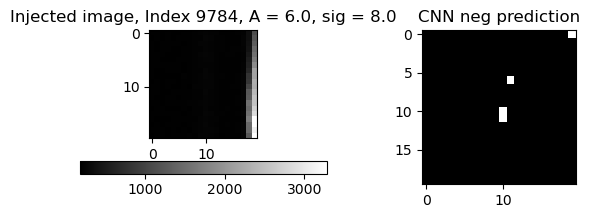

In [36]:
rff.inspect_stamp_and_map(dfs_pos["original"], 9784, posneg="pos", size=10,pdirec='predsarrays')

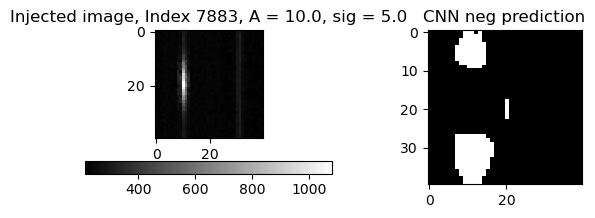

In [37]:
rff.inspect_stamp_and_map(dfs_pos["original"], 7883, size=20,posneg="pos",pdirec='predsarrays')

In [ ]:
df_paths = ["predsarrays/",
                "presdarrays_flipped/",
                "presdarrays_both/",
                "predsarrays_dup/"]

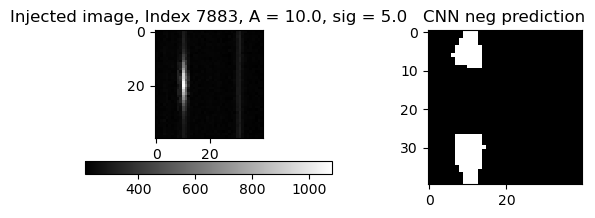

In [40]:
rff.inspect_stamp_and_map(dfs_pos["original"], 7883, size=20,posneg="pos",pdirec=df_paths[3][:-1])

In [72]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

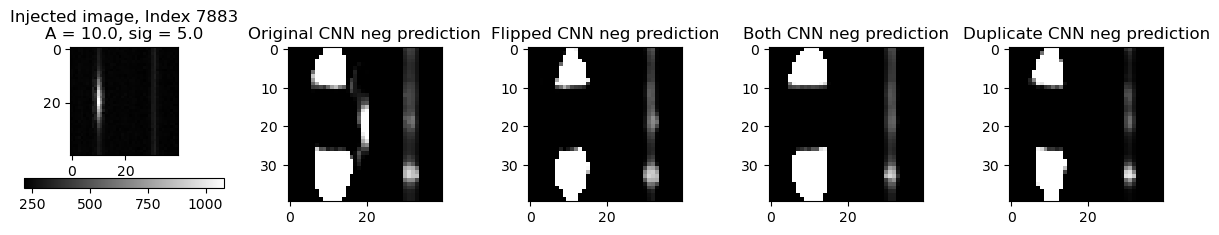

In [78]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", thr=False)

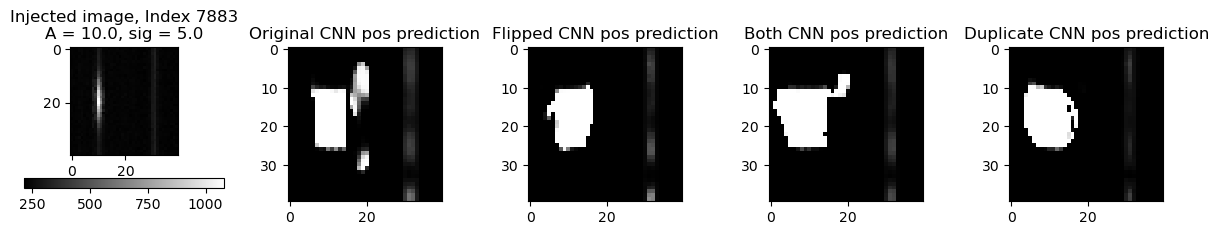

In [79]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", thr=False, override="pos")

In [58]:
dfs_pos["original"].loc[23622]

Unnamed: 0.1                                              23622
Unnamed: 0                                                23622
filename               ztf_20221017148750_000831_zi_c04_x_0015.
quad                                                          1
type                                                        neg
row_from_nn                                          764.714286
col_from_nn                                               214.0
detection_size                                                7
closest_x                                                 234.0
closest_y                                                1787.0
Diff                                                       10.0
brightness_ranking                                           21
quadrant                                                      1
num_in_file_in_star                                         2.0
dup_indices                                             [23621]
is_smaller_dup                          

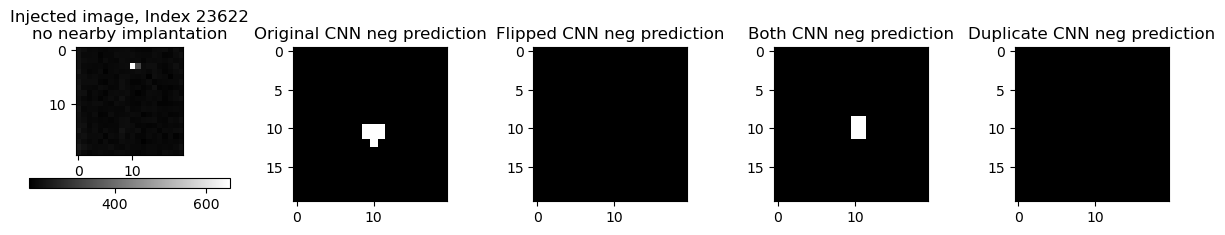

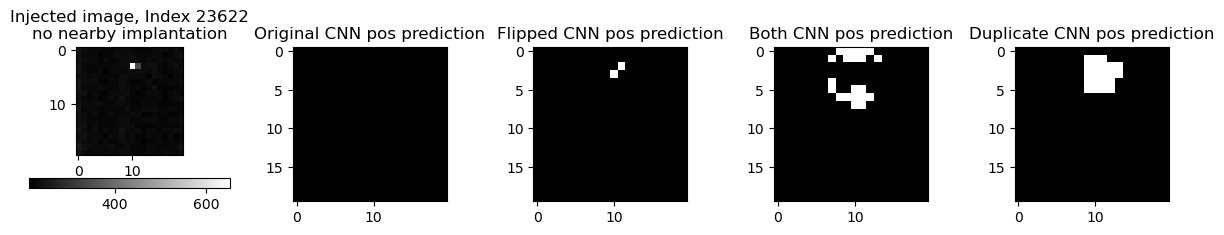

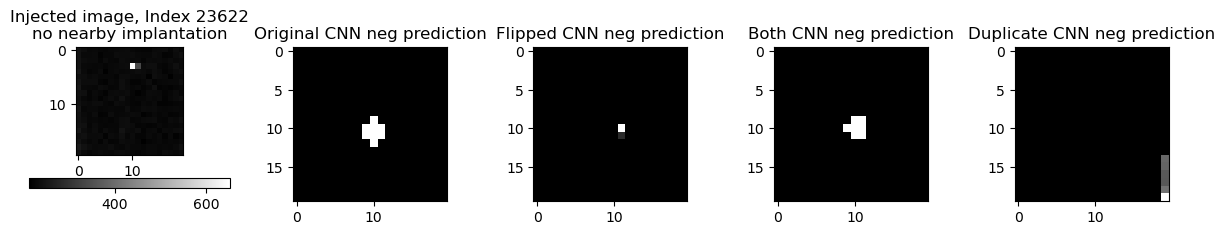

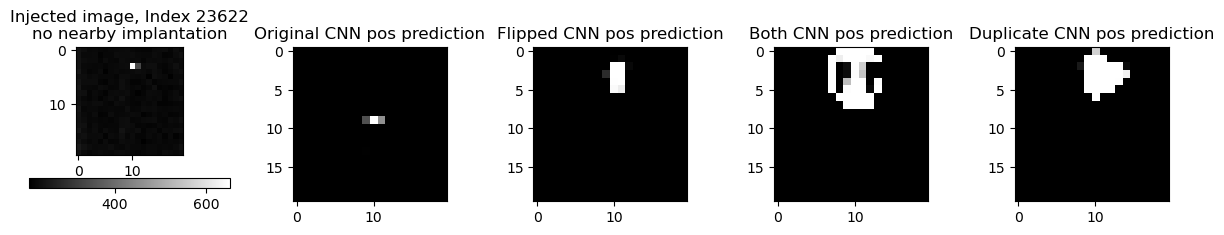

In [116]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23622, size=10,posneg="pos", thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23622, size=10,posneg="pos", override="pos",thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23622, size=10,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23622, size=10,posneg="pos", override="pos", thr=False)


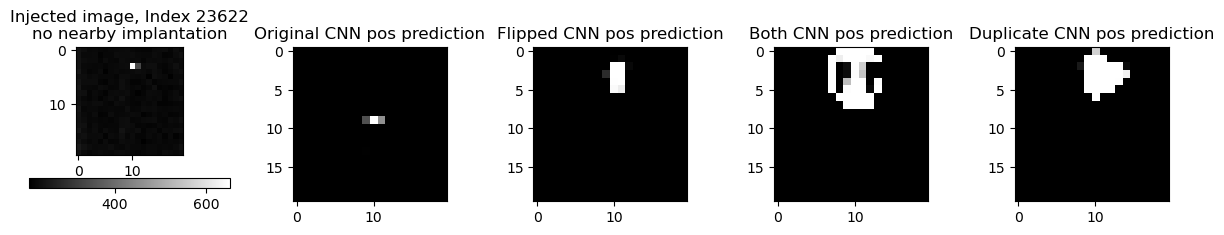

In [74]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23622, size=10,posneg="pos", override="pos", thr=False)

In [83]:
dfs_pos["original"][(dfs_pos["original"]['Diff']<=10)*(dfs_pos["original"]['Diff']>=9)]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
47,47,47,ztf_20220820237546_000798_zr_c09_x_0004.,1,neg,769.000000,1902.0,21,1921.0,129.0,...,0,1,8.0,[46 48 49],1.0,11.045361,778.0,1923.0,2.0,9.0
6093,6093,6093,ztf_20221014162894_000802_zg_c02_x_0003.,1,neg,374.000000,1537.0,1,1556.0,2919.0,...,1,1,121.0,[6092 6094],1.0,15.556349,395.0,1558.0,6.0,8.0
6868,6868,6868,ztf_20221014162894_000802_zg_c01_x_0027.,1,neg,1682.000000,536.0,1,555.0,959.0,...,2,1,56.0,[6867 6869],1.0,12.806248,1700.0,556.0,6.0,5.0
7883,7883,7883,ztf_20221017148750_000831_zi_c04_x_0012.,1,neg,1871.000000,93.0,5,113.0,238.0,...,7,1,1.0,[7882 7884],1.0,10.049876,1880.0,93.0,10.0,5.0
7978,7978,7978,ztf_20221017148750_000831_zi_c03_x_0021.,1,neg,573.000000,437.0,1,456.0,2060.0,...,0,1,15.0,[7977 7979 7980],1.0,14.142136,593.0,457.0,8.0,7.0
8325,8325,8325,ztf_20221020138241_000686_zi_c01_x_0001.,1,neg,2895.000000,1764.0,1,1783.0,1737.0,...,0,1,129.0,[8324 8326],1.0,12.206556,2912.0,1784.0,8.0,5.0
9359,9359,9359,ztf_20220820237546_000798_zr_c13_x_0004.,1,neg,885.000000,304.0,1,323.0,1565.0,...,0,1,193.0,[9358 9360 9361],1.0,15.000000,904.0,326.0,8.0,6.0
9783,9783,9783,ztf_20221017148750_000831_zi_c03_x_0015.,1,neg,294.000000,437.0,1,456.0,2060.0,...,0,1,9.0,[9782 9784 9785],1.0,15.556349,315.0,458.0,6.0,8.0
9784,9784,9784,ztf_20221017148750_000831_zi_c03_x_0015.,1,neg,298.500000,436.0,2,456.0,2060.0,...,0,1,9.0,[9782 9783],1.0,13.647344,315.0,458.0,6.0,8.0
14037,14037,14037,ztf_20221017148750_000831_zi_c03_x_0013.,1,neg,2742.000000,437.0,1,456.0,2060.0,...,0,1,10.0,[14036 14038],1.0,16.278821,2764.0,458.0,8.0,9.0


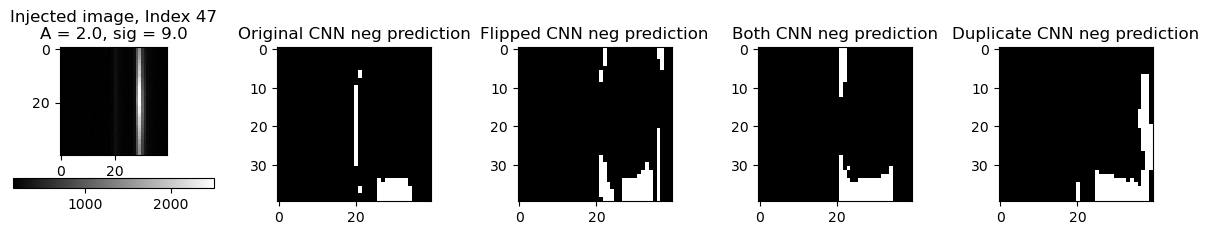

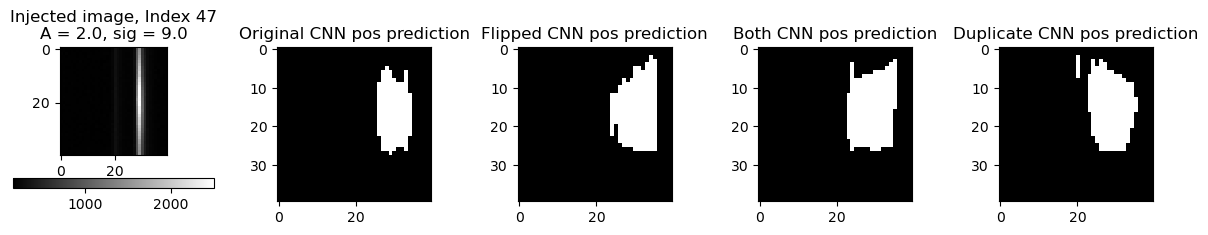

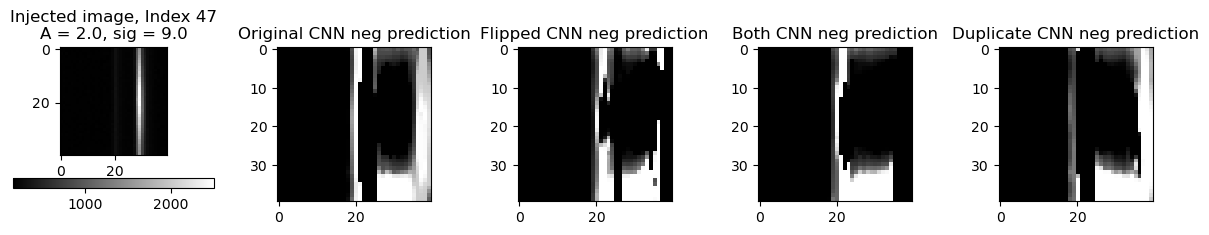

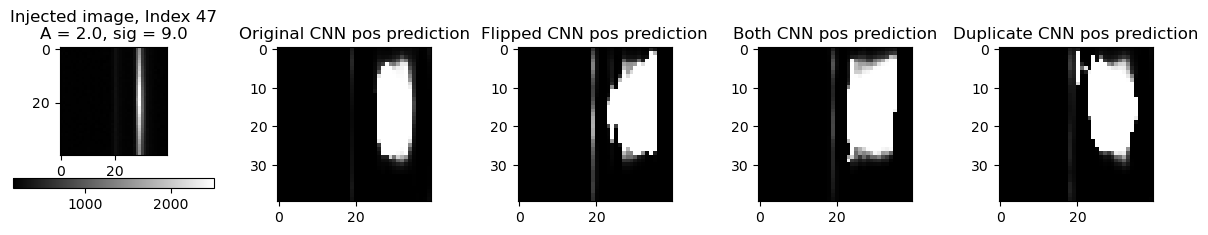

In [117]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 47, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 47, size=20,posneg="pos", override="pos", thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 47, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 47, size=20,posneg="pos", override="pos", thr=False)

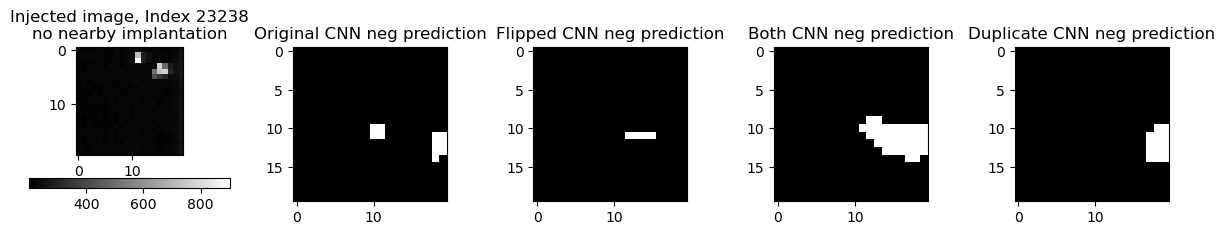

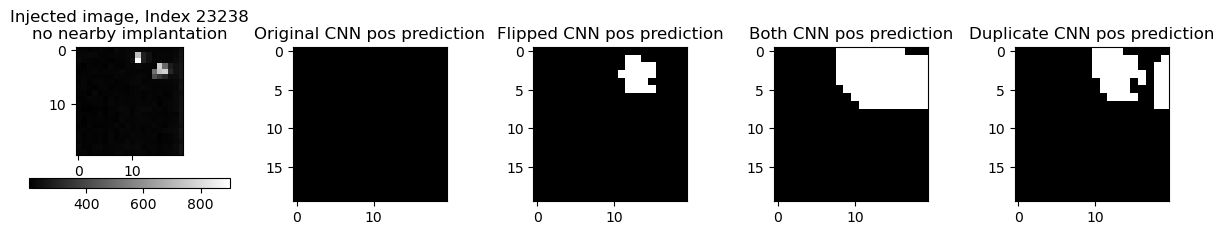

In [89]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23238, size=10,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 23238, size=10,posneg="pos", override="pos", thr=True)


In [91]:
dfs_pos["original"][(dfs_pos["original"]['dist_to_implant']<=10)*(dfs_pos["original"]['dist_to_implant']>=5)]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
8,8,8,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,2015.500000,2793.000000,2,2806.0,2701.0,...,7,1,3.0,[7],1.0,6.800735,2031.0,2799.0,3.00,6.0
17,17,17,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,1330.357143,1331.714286,14,1331.0,1567.0,...,5,1,4.0,[19],1.0,9.808628,1339.0,1332.0,6.00,8.0
24,24,24,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,1985.500000,1606.600000,10,1608.0,1444.0,...,6,1,4.0,[23 25],1.0,8.729834,1994.0,1608.0,6.00,7.0
27,27,27,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,2021.466667,2797.333333,30,2806.0,2701.0,...,7,1,3.0,[26 28],1.0,8.346390,2031.0,2799.0,3.00,6.0
34,34,34,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,2942.181818,160.590909,22,169.0,2559.0,...,0,1,4.0,[35],0.0,9.190927,2943.0,171.0,1.15,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29808,29808,29808,ztf_20221020138241_000686_zi_c02_x_0001.,1,neg,2269.968750,379.875000,32,380.0,1860.0,...,1,1,172.0,[29806 29807 29809],1.0,8.875055,2280.0,381.0,8.00,4.0
29969,29969,29969,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,2576.500000,317.000000,4,320.0,1610.0,...,5,1,3.0,[29968],1.0,7.500000,2591.0,321.0,3.00,8.0
29975,29975,29975,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,2769.460064,1908.389776,313,1916.0,215.0,...,2,1,4.0,[],0.0,5.553631,2785.0,1918.0,10.00,9.0
29993,29993,29993,ztf_20221014162894_000802_zg_c02_x_0017.,1,neg,291.727273,2317.181818,33,2316.0,2430.0,...,0,1,24.0,[29991 29992 29994],1.0,8.186362,302.0,2319.0,8.00,3.0


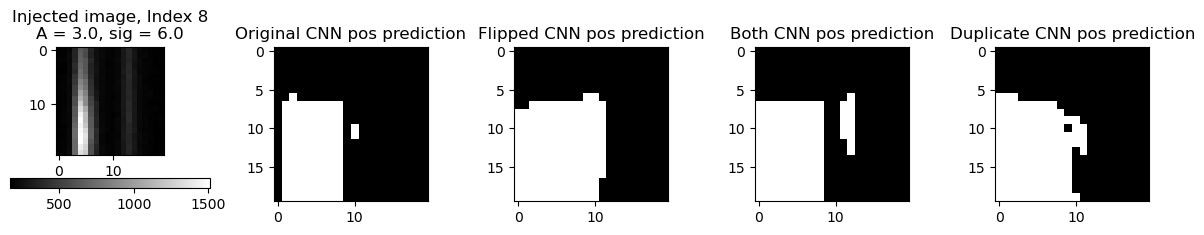

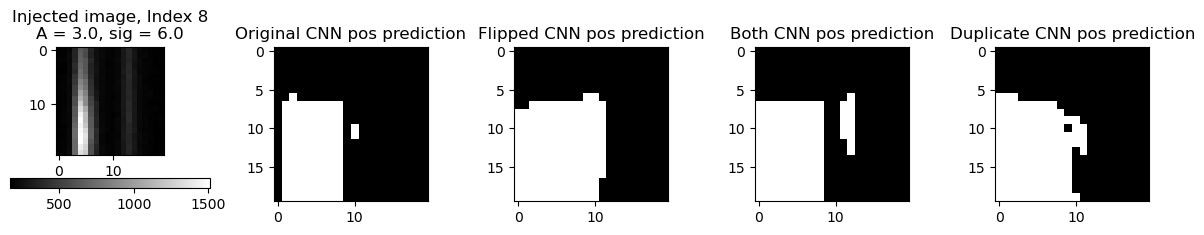

In [92]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 8, size=10,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 8, size=10,posneg="pos", override="pos", thr=True)


In [93]:
orig_nodup = dfs_pos["original"][dfs_pos["original"]['is_smaller_dup']==False]
orig_nodup[(orig_nodup['dist_to_implant']<=10)*(orig_nodup['dist_to_implant']>=5)]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
34,34,34,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,2942.181818,160.590909,22,169.0,2559.0,...,0,1,4.0,[35],0.0,9.190927,2943.0,171.0,1.15,3.0
223,223,223,ztf_20221017148750_000831_zi_c03_x_0024.,1,neg,1149.133333,3004.466667,15,3016.0,1655.0,...,16,1,1.0,[],0.0,8.669999,1161.0,3006.0,6.00,8.0
569,569,569,ztf_20221020138241_000686_zi_c01_x_0004.,1,neg,2069.625000,762.687500,16,762.0,373.0,...,11,1,8.0,[],0.0,9.707640,2079.0,763.0,10.00,9.0
593,593,593,ztf_20221017148750_000831_zi_c04_x_0027.,1,neg,592.117647,84.000000,51,93.0,916.0,...,11,1,3.0,[],0.0,9.882353,612.0,94.0,6.00,3.0
976,976,976,ztf_20221017148750_000831_zi_c03_x_0003.,1,neg,220.200000,1934.600000,15,1934.0,651.0,...,1,1,9.0,[],0.0,8.637129,231.0,1936.0,6.00,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28923,28923,28923,ztf_20221014162894_000802_zg_c03_x_0008.,1,neg,2091.500000,690.000000,6,702.0,1715.0,...,21,1,6.0,[],0.0,8.015610,2102.0,692.0,4.00,9.0
29041,29041,29041,ztf_20221020138241_000686_zi_c02_x_0016.,1,pos,951.293103,2958.551724,58,2967.0,428.0,...,3,1,84.0,[29039 29042],0.0,5.733504,967.0,2968.0,1.50,9.0
29203,29203,29203,ztf_20221020138241_000686_zi_c02_x_0016.,1,pos,2376.656934,481.762774,274,489.0,434.0,...,2,1,85.0,[],0.0,6.015087,2392.0,489.0,4.00,8.0
29790,29790,29790,ztf_20221020138241_000686_zi_c02_x_0001.,1,neg,565.351351,22.486486,37,23.0,1945.0,...,4,1,3.0,[],0.0,9.492991,575.0,23.0,10.00,5.0


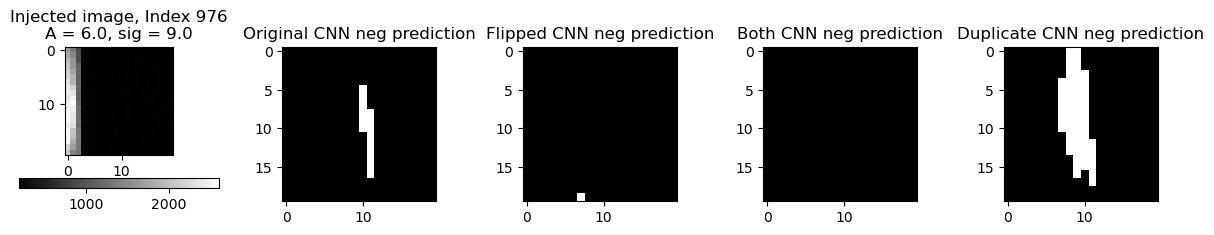

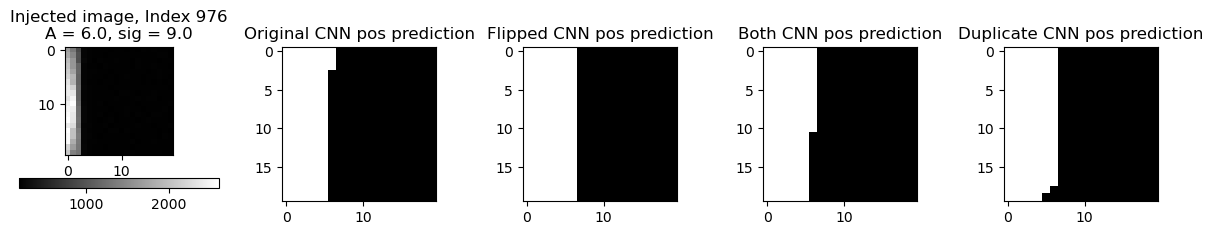

In [94]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 976, size=10,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 976, size=10,posneg="pos", override="pos", thr=True)


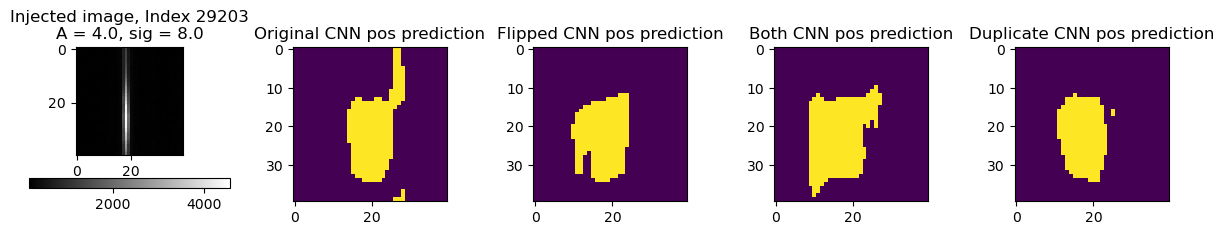

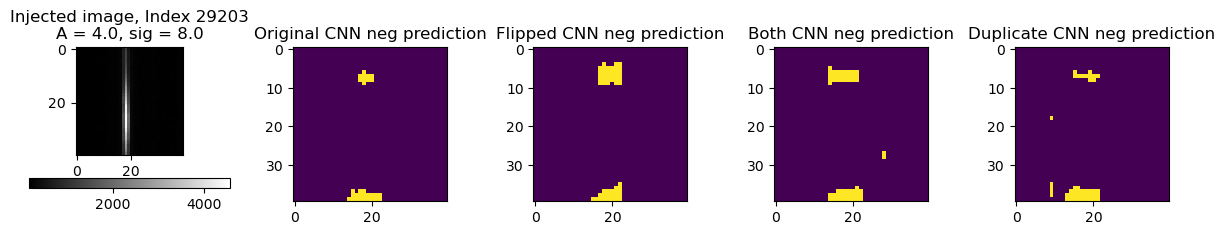

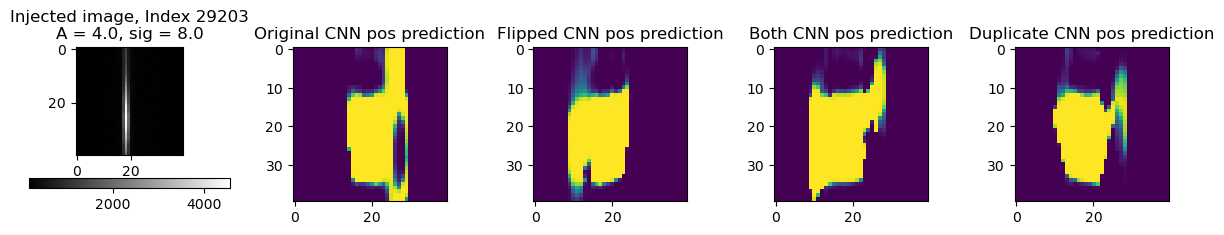

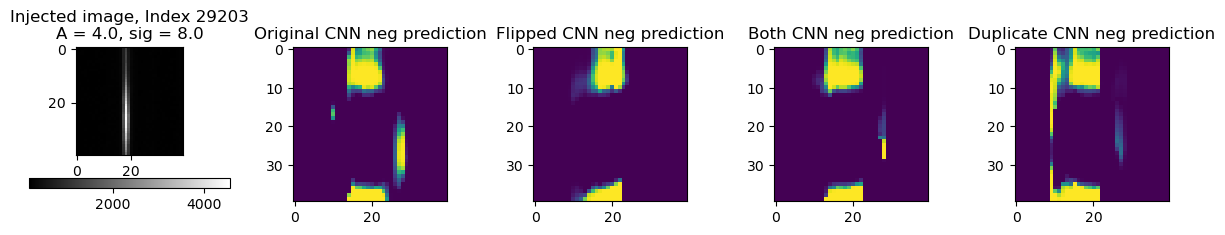

In [143]:

rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos", override="neg", thr=True)

rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29203, size=20,posneg="pos", override="neg", thr=False)


In [111]:
orig_nodup[(orig_nodup['dist_to_implant']>=500)]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
5,5,5,ztf_20221014162894_000802_zg_c01_x_0005.,1,pos,1893.733333,1078.200000,15,1132.0,1589.0,...,9,1,10.0,[],0.0,527.579483,1994.0,1608.0,6.00,7.0
22,22,22,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,1901.714286,1079.857143,7,1132.0,1589.0,...,9,1,10.0,[20 21],0.0,524.636025,1994.0,1608.0,6.00,7.0
30,30,30,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,2701.000000,2797.000000,1,2806.0,2701.0,...,7,1,3.0,[],0.0,680.047057,2031.0,2799.0,3.00,6.0
33,33,33,ztf_20221014162894_000802_zg_c01_x_0005.,1,neg,2782.000000,1146.500000,12,1132.0,1589.0,...,9,1,10.0,[31 32],0.0,871.982368,2591.0,2005.0,1.15,8.0
57,57,57,ztf_20221020138241_000686_zi_c01_x_0013.,1,pos,25.500000,1693.000000,2,1693.0,2913.0,...,1,1,40.0,[],0.0,635.079719,346.0,2257.0,1.20,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29904,29904,29904,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,1437.000000,1555.000000,7,1556.0,2919.0,...,1,1,146.0,[],0.0,561.601282,1783.0,2015.0,10.00,3.0
29905,29905,29905,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,1475.888889,1554.740741,27,1556.0,2919.0,...,1,1,146.0,[],0.0,539.451956,1783.0,2015.0,10.00,3.0
29906,29906,29906,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,1511.928571,1554.571429,14,1556.0,2919.0,...,1,1,146.0,[],0.0,520.619044,1783.0,2015.0,10.00,3.0
29907,29907,29907,ztf_20221014162894_000802_zg_c02_x_0017.,1,pos,1537.500000,1555.000000,8,1556.0,2919.0,...,1,1,146.0,[],0.0,507.897874,1783.0,2015.0,10.00,3.0


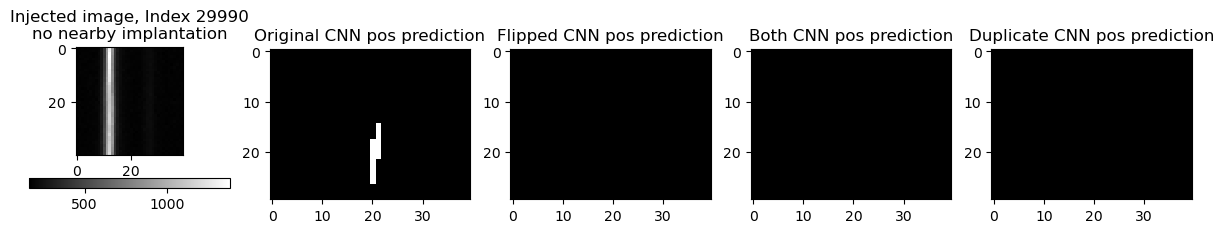

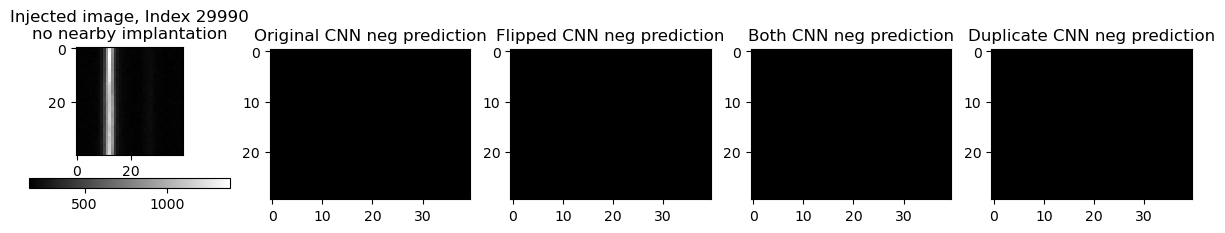

In [102]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29990, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 29990, size=20,posneg="pos", override="neg", thr=True)


In [118]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

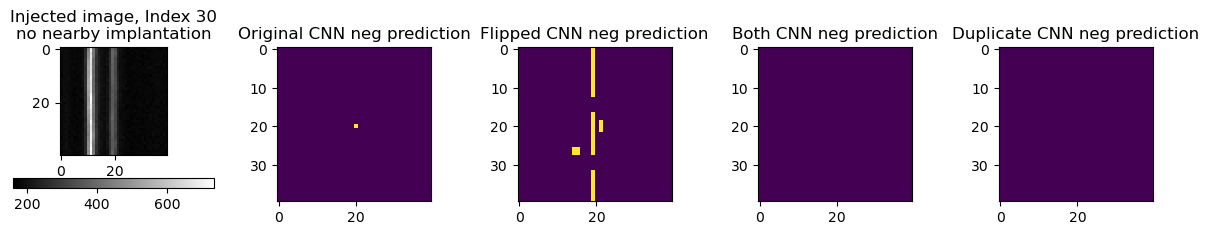

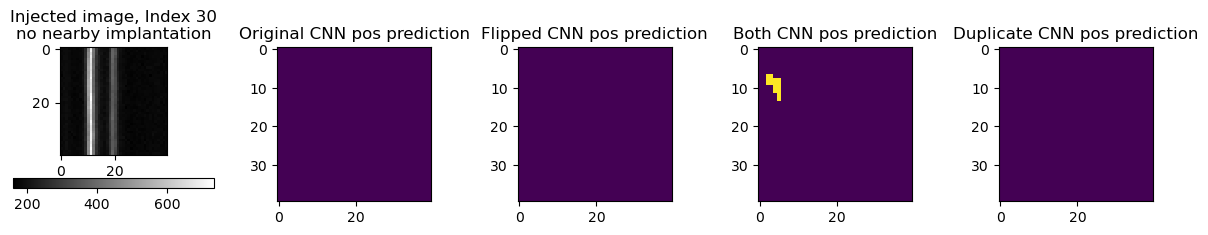

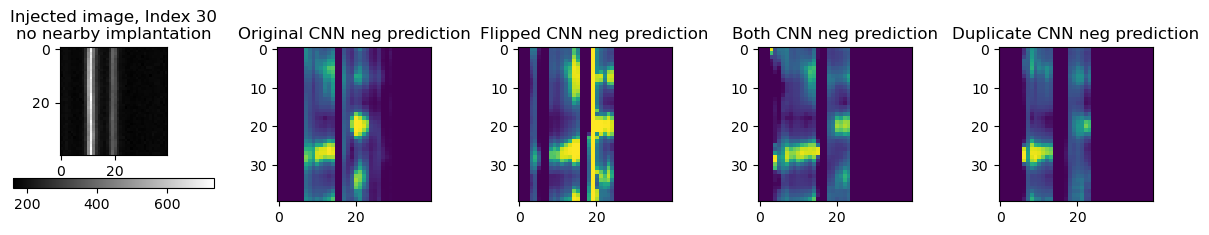

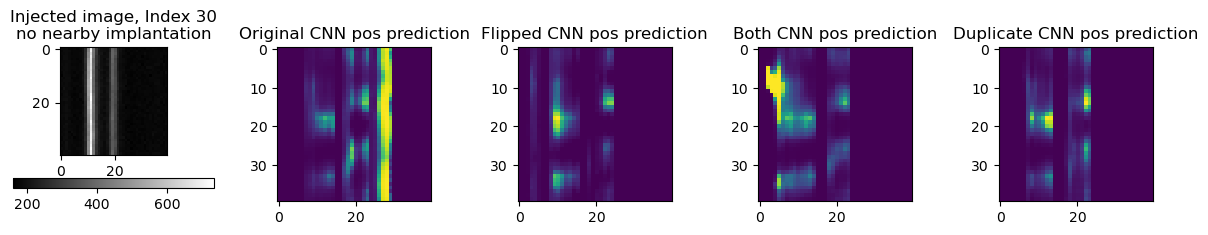

In [119]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 30, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 30, size=20,posneg="pos", override="pos", thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 30, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 30, size=20,posneg="pos", override="pos", thr=False)


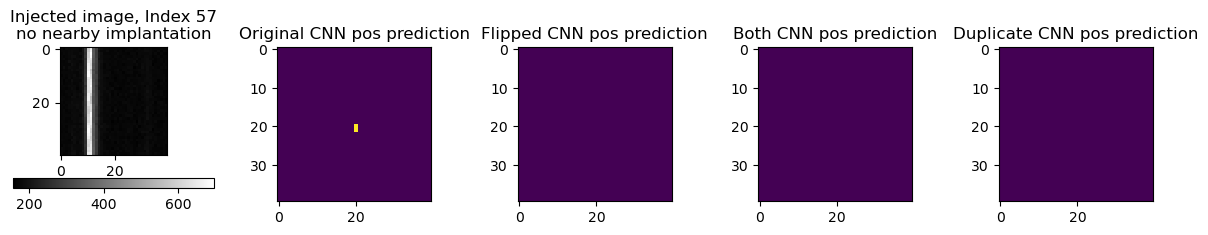

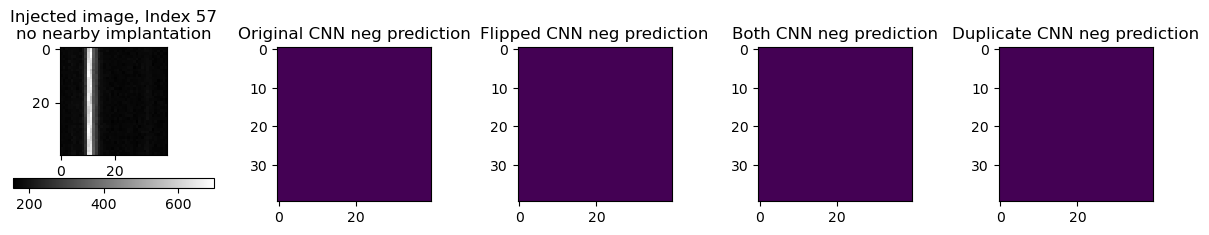

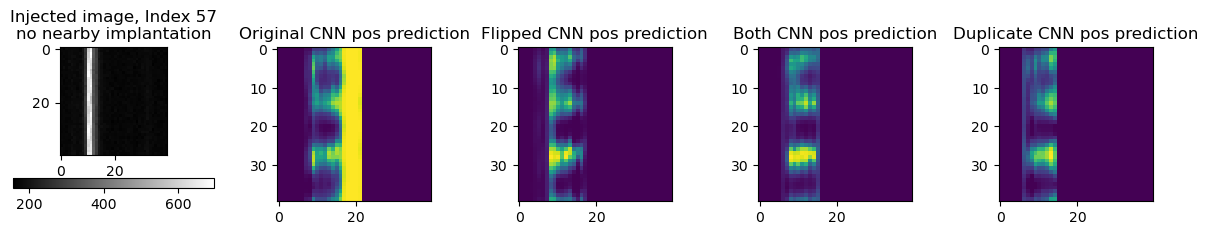

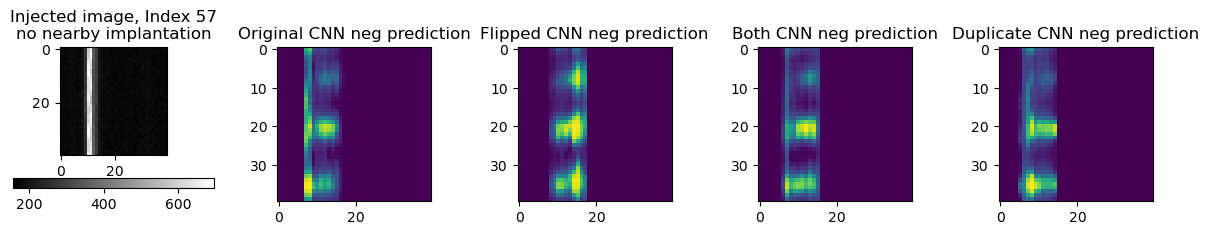

In [140]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 57, size=20,posneg="pos",  thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 57, size=20,posneg="pos", override="neg", thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 57, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 57, size=20,posneg="pos", override="neg", thr=False)


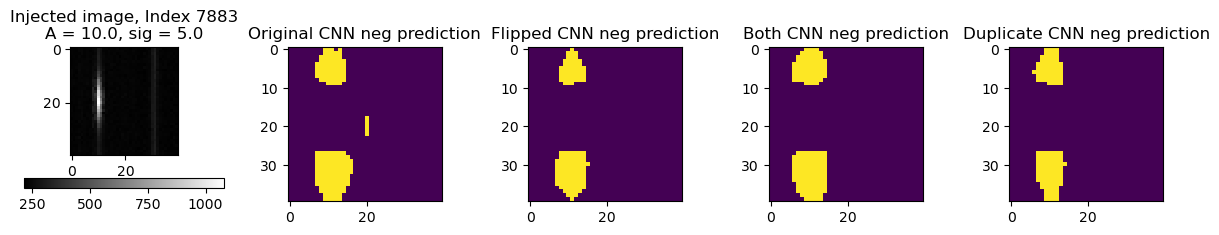

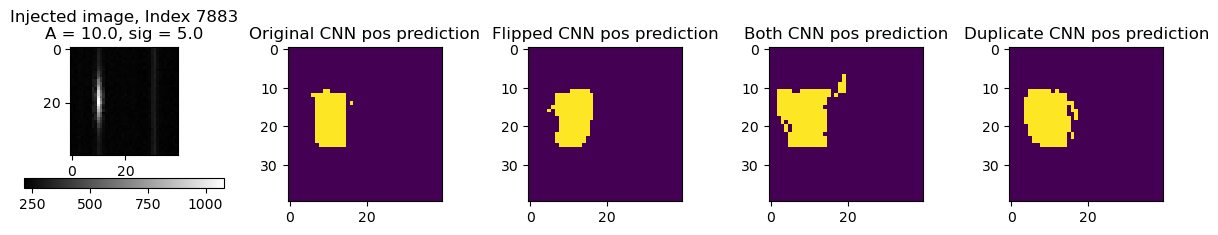

under here not thresholded


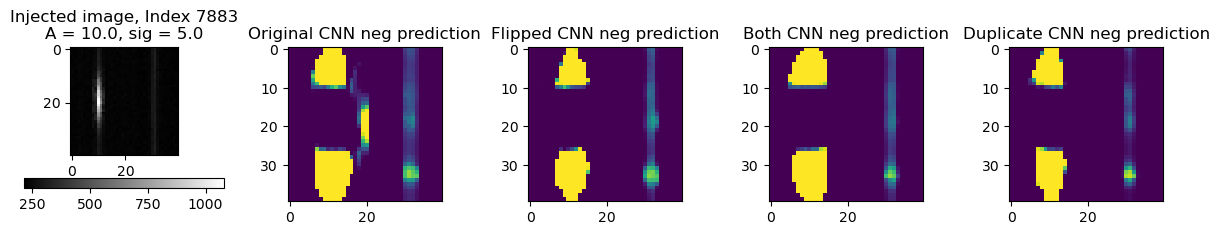

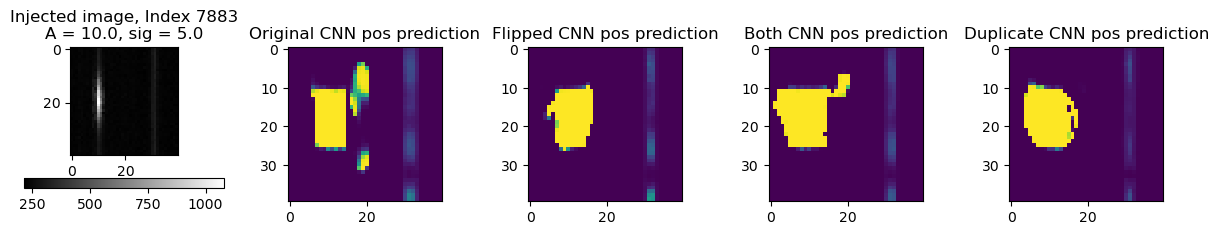

In [124]:
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", thr=True)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", override="pos", thr=True)
print("under here not thresholded")
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_pos["original"], 7883, size=20,posneg="pos", override="pos", thr=False)

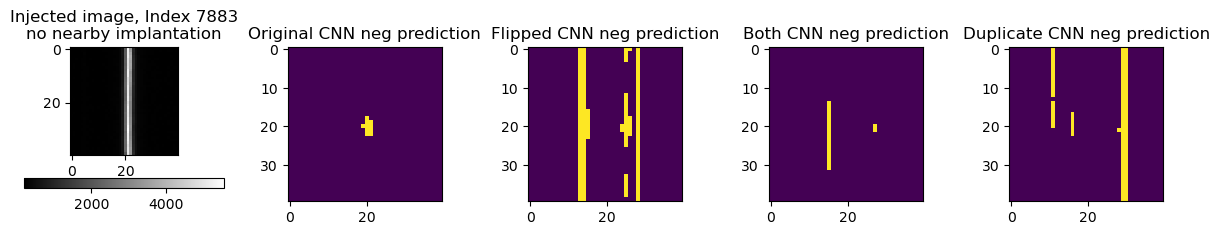

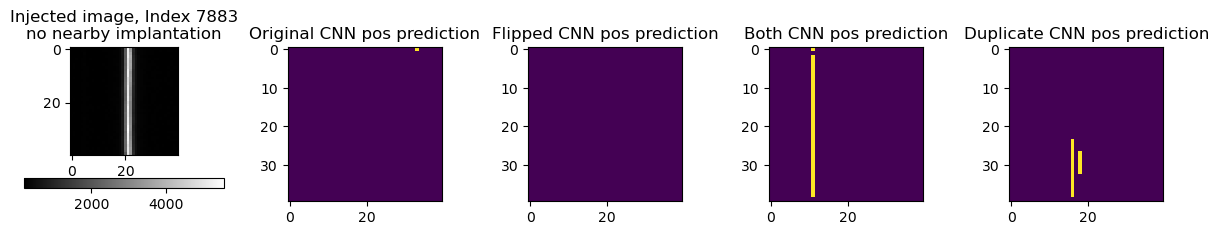

under here not thresholded


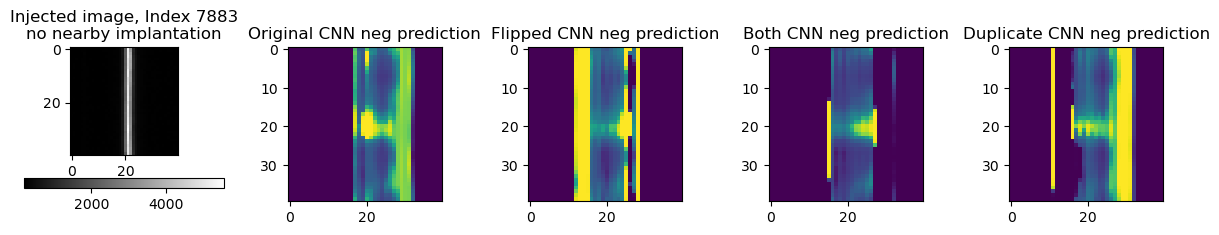

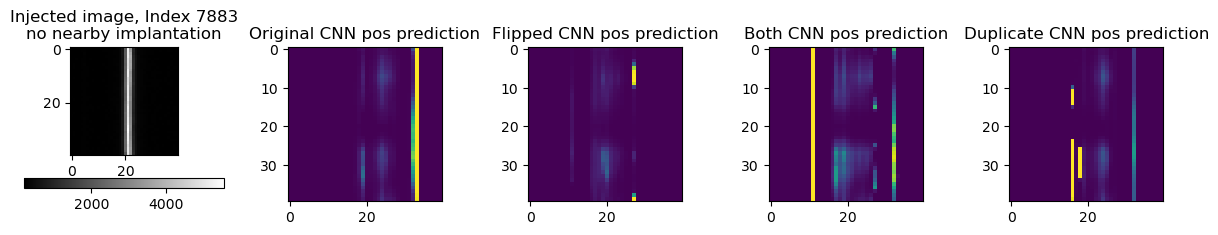

In [126]:
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 7883, size=20,posneg="neg", thr=True)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 7883, size=20,posneg="neg", override="pos", thr=True)
print("under here not thresholded") 
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 7883, size=20,posneg="neg",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 7883, size=20,posneg="neg", override="pos", thr=False)

In [127]:
dfs_neg["original"]

,Unnamed: 0.1,Unnamed: 0,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,...,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
0,0,0,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,316.000000,1735.400000,15,1752.0,1883.0,...,9,1,6.0,[],0.0,327.384422,595.0,1932.0,0.90,9.0
1,1,1,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,910.736842,91.578947,19,93.0,916.0,...,11,1,3.0,[],0.0,480.813383,440.0,93.0,0.85,5.0
2,2,2,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,1340.500000,448.000000,4,458.0,1367.0,...,0,1,16.0,[],0.0,8.732125,1342.0,460.0,0.90,6.0
3,3,3,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,1899.718750,2581.687500,32,2627.0,543.0,...,17,1,3.0,[],0.0,665.638736,2518.0,2862.0,0.80,8.0
4,4,4,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,2513.500000,448.000000,4,458.0,1367.0,...,0,1,16.0,[],0.0,195.077549,2518.0,263.0,0.50,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24031,24031,24031,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2593.000000,515.000000,1,526.0,1639.0,...,1,1,41.0,[],0.0,317.855313,2297.0,439.0,0.70,7.0
24032,24032,24032,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2747.000000,514.000000,3,526.0,1639.0,...,1,1,41.0,[],0.0,467.787345,2297.0,439.0,0.70,7.0
24033,24033,24033,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2769.000000,514.000000,3,526.0,1639.0,...,1,1,41.0,[],0.0,489.437432,2297.0,439.0,0.70,7.0
24034,24034,24034,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2916.000000,957.000000,1,968.0,825.0,...,0,1,16.0,[],0.0,452.305207,2500.0,1119.0,0.80,4.0


In [136]:
dfs_neg["original"][dfs_neg["original"]['dist_to_implant']<10].drop(columns=['Unnamed: 0', 'Unnamed: 0.1'])

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
2,ztf_20221017148750_000831_zi_c04_x_0015.,1,pos,1340.500000,448.000000,4,458.0,1367.0,0.000000,0,1,16.0,[],0.0,8.732125,1342.0,460.0,0.90,6.0
20,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,1331.878788,449.878788,33,458.0,1367.0,-1.878788,0,1,16.0,[21],0.0,0.171420,1342.0,460.0,0.90,6.0
21,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,1332.000000,445.000000,1,458.0,1367.0,3.000000,0,1,16.0,[20],1.0,5.000000,1342.0,460.0,0.90,6.0
29,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,2505.666667,2851.666667,3,2861.0,1404.0,-0.666667,3,1,1.0,[],0.0,2.357023,2518.0,2862.0,0.80,8.0
30,ztf_20221017148750_000831_zi_c04_x_0015.,1,neg,2509.600000,253.800000,5,263.0,828.0,-0.800000,8,1,1.0,[],0.0,1.788854,2518.0,263.0,0.50,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24008,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1364.238095,958.158730,63,968.0,825.0,-0.158730,0,1,16.0,[],0.0,1.135004,1375.0,969.0,0.70,9.0
24015,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1806.547619,2355.071429,42,2366.0,541.0,0.928571,2,1,8.0,[],0.0,2.414290,1818.0,2367.0,0.85,8.0
24017,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,1969.333333,1909.166667,6,1918.0,2162.0,-1.166667,3,1,1.0,[],0.0,0.687184,1980.0,1919.0,0.90,5.0
24022,ztf_20221020138241_000686_zi_c03_x_0015.,1,neg,2287.033898,428.288136,59,438.0,147.0,-0.288136,4,1,5.0,[],0.0,0.712671,2297.0,439.0,0.70,7.0


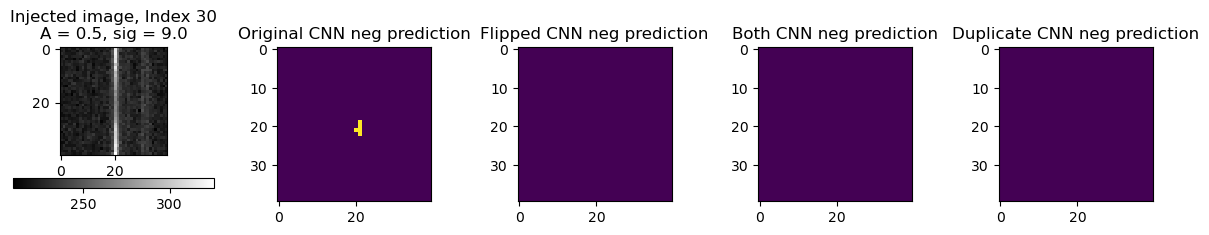

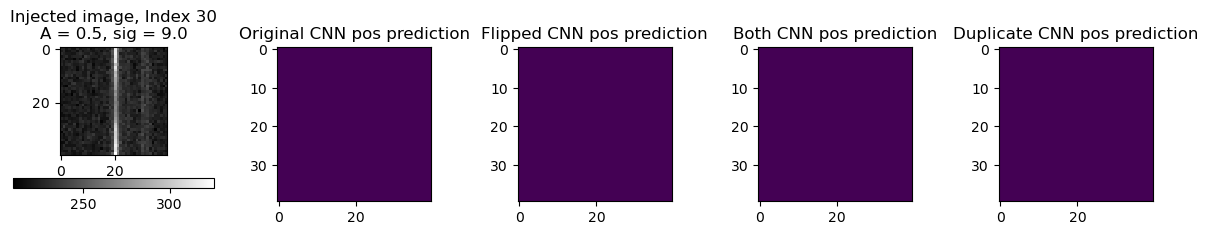

under here not thresholded


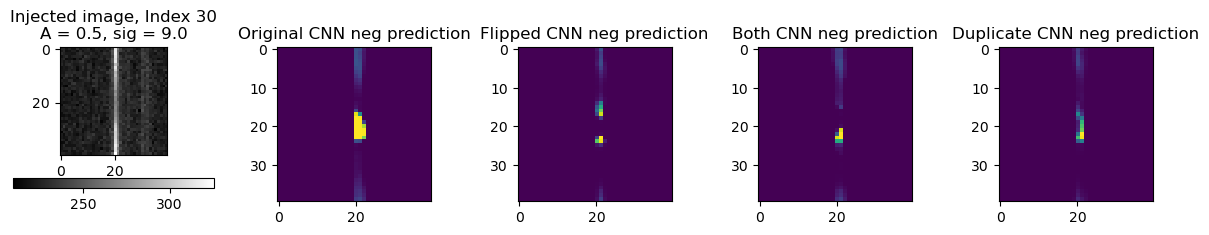

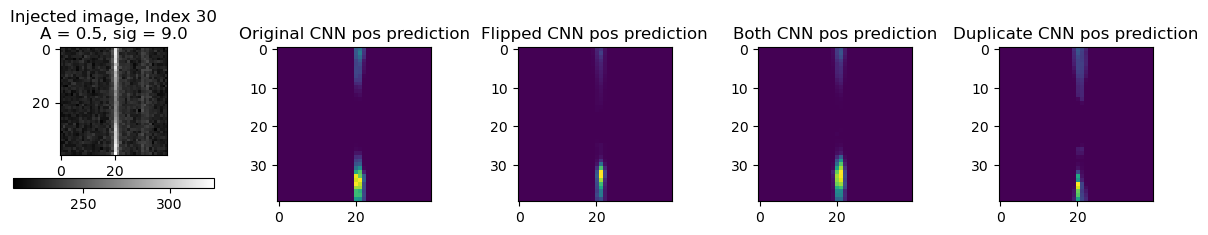

In [131]:
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 30, size=20,posneg="neg", thr=True)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 30, size=20,posneg="neg", override="pos", thr=True)
print("under here not thresholded")  
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 30, size=20,posneg="neg",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 30, size=20,posneg="neg", override="pos", thr=False)

In [139]:
rff.inspect_stamp_and_all_maps?

Signature:
rff.inspect_stamp_and_all_maps(
    df,
    index,
    eff=True,
    posneg=None,
    size=10,
    column=None,
    nn_or_imp='nn',
    thr=True,
    star=False,
    override=False,
)
Docstring: for efficiency data
File:      ~/rwe/review_findings_functions.py
Type:      function

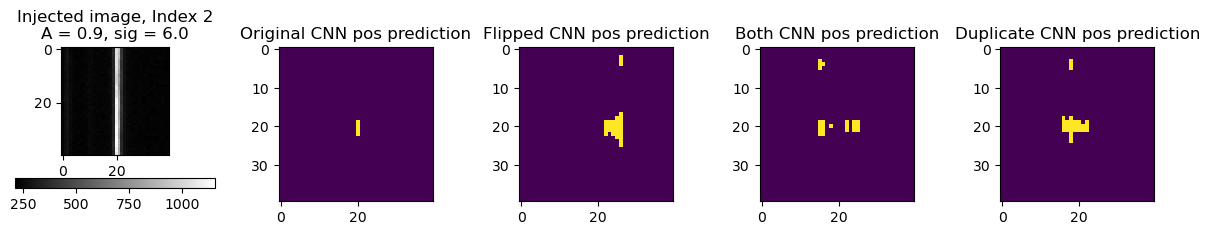

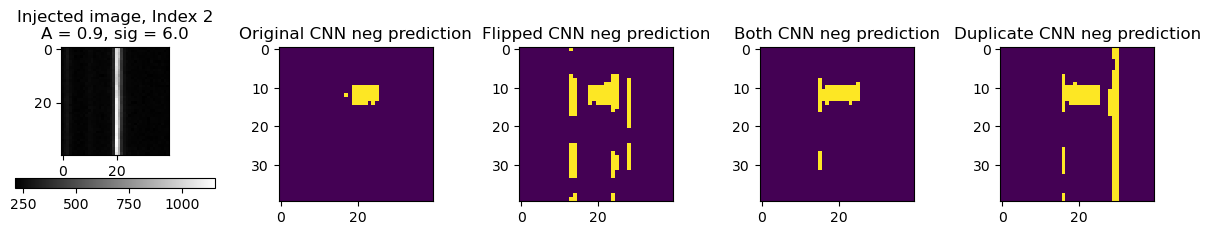

under here not thresholded


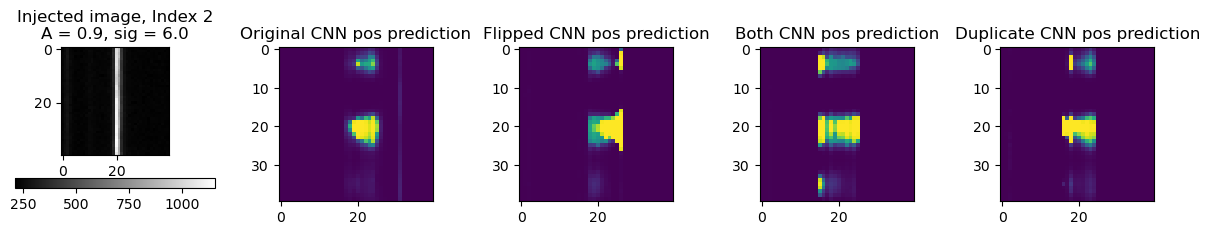

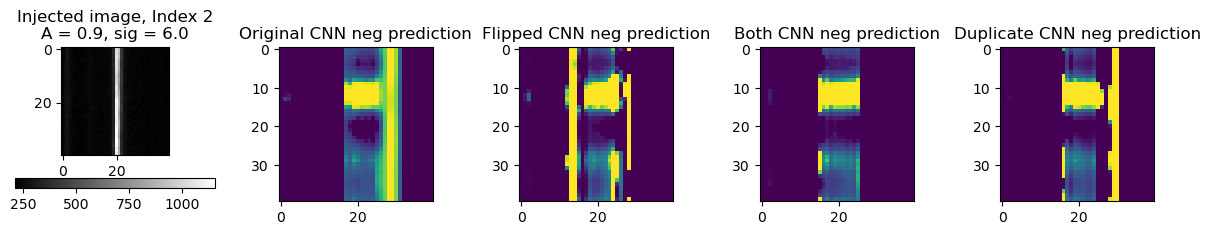

In [144]:
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 2, size=20,posneg="neg", thr=True)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 2, size=20,posneg="neg", override="neg", thr=True)
print("under here not thresholded")
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 2, size=20,posneg="neg",  thr=False)
rff.inspect_stamp_and_all_maps(dfs_neg["original"], 2, size=20,posneg="neg", override="neg", thr=False)